# 07 — Síntesis de resultados: cuántico vs clásico

Este cuaderno **no contiene ningún resultado escrito a mano**. Consolida las salidas ejecutadas de los nueve casos de uso
(notebooks 01, 03, 04, 06 y los protocolos `qml_v2`) con `scripts/sintesis_resultados.py` en `07_sintesis_resultados.csv`
y dibuja el panel con `scripts/generar_dashboard_ventaja.py` a partir de ese único CSV.

Convención: `valor` es la ventaja del método cuántico sobre el mejor clásico en la unidad indicada; positivo favorece al cuántico.
Antes de ejecutarlo deben existir los CSV de los casos de uso; si falta alguno, la síntesis falla en lugar de rellenar con valores de ejemplo.

In [1]:
import sys
from pathlib import Path

from IPython.display import Image, display

POCS = Path("..").resolve()
sys.path.insert(0, str(POCS / "scripts"))

import sintesis_resultados as sintesis

tabla = sintesis.consolidar()
tabla.to_csv(sintesis.SALIDA, index=False)
tabla

,caso,capa,etiqueta,valor,unidad,fuente
0,1,nativo,QSVM,38.3,pp,NB01 §13.6
1,1,skg,QSVM,-4.5,pp,NB01 §13.6
2,1,referencia,QSVM,-3.8,pp,NB01 §13.6
3,2,nativo,QK-SVR,96.5,ΔR²×100,NB03 §13.5
4,2,skg,QK-SVR,-56.2,ΔR²×100,NB03 §13.5
5,2,referencia,QK-SVR,-92.8,ΔR²×100,NB03 §13.5
6,3,referencia,QAOA p=1,0.0,% coste,qml_v2.optimization
7,4,referencia,VQE (5 reinicios),-34.0,% brecha,NB04 §11
8,5,referencia,QAOA p=1,0.0,pp brecha,qml_v2.tsp_optimization
9,6,nativo,QSVC,8.9,pp,NB06 §5


## Panel de ventaja por caso de uso

Dashboard guardado: 07_dashboard_ventaja_cuantica.png
Condicional         5
Empate              2
Clásico superior    2


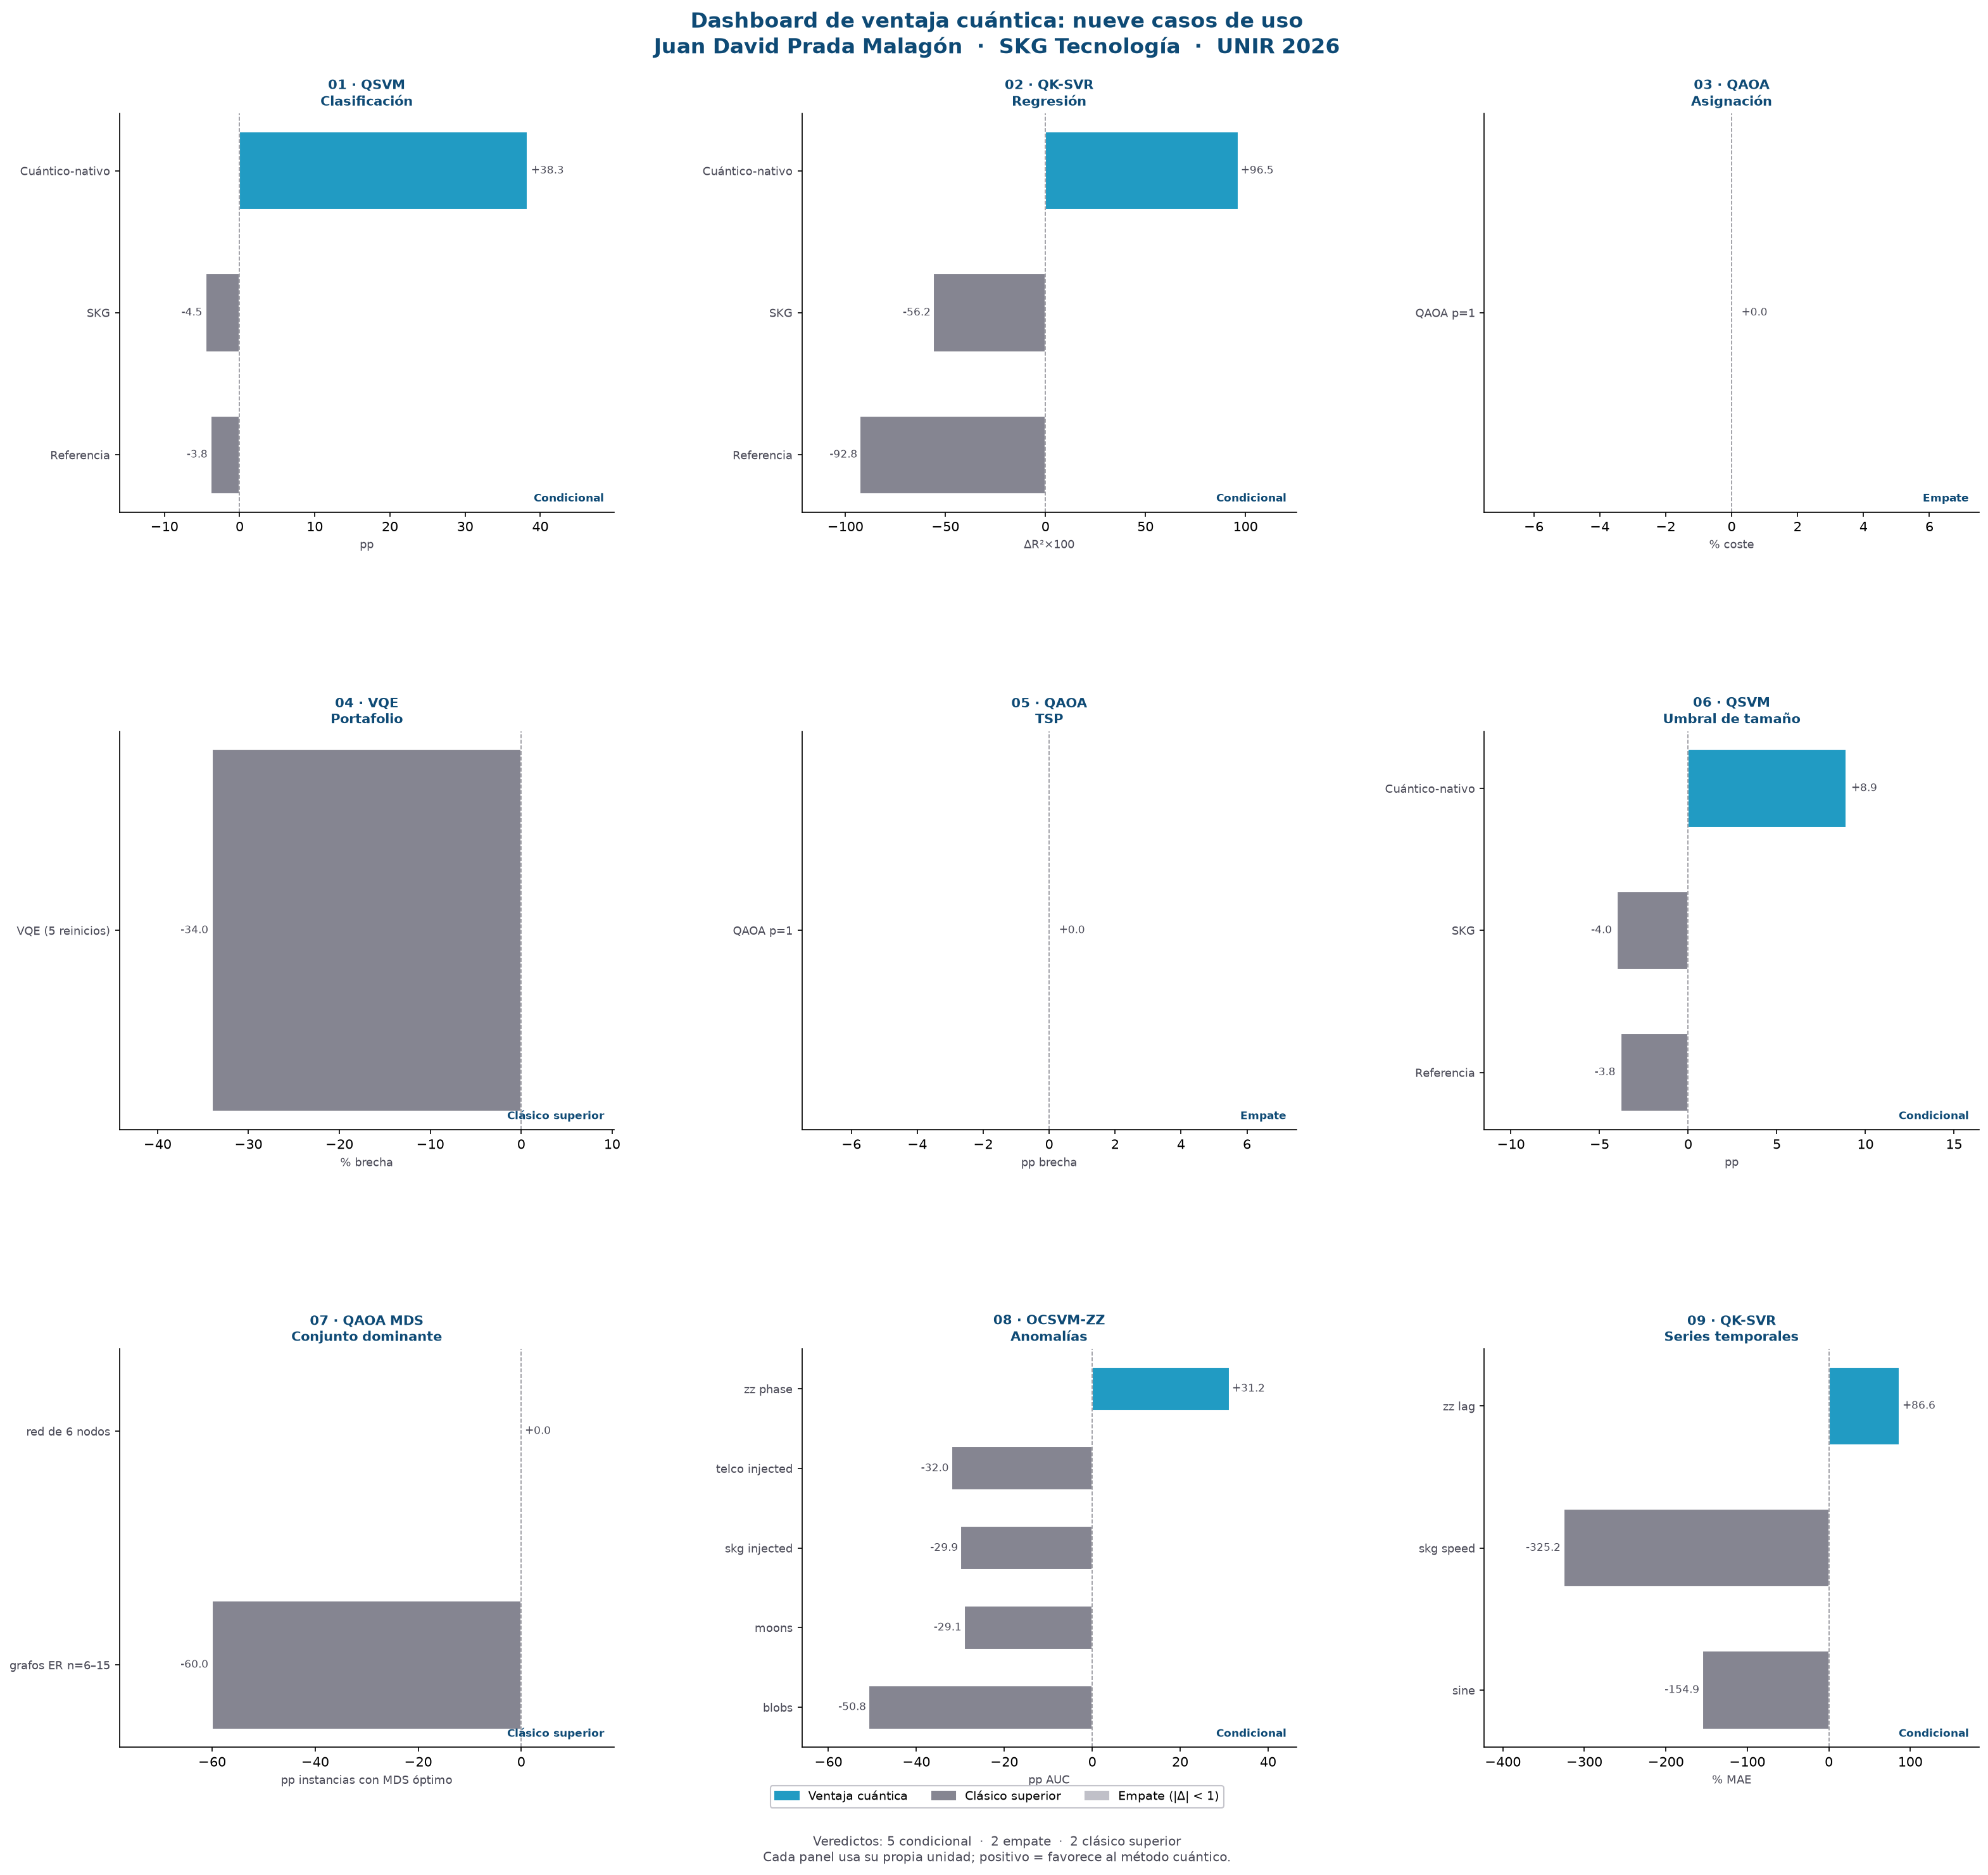

In [2]:
import generar_dashboard_ventaja as dashboard

dashboard.main()
display(Image(filename=str(dashboard.SALIDA)))

## Lectura

- La ventaja del método cuántico aparece solo en las capas con estructura alineada con el mapa de características (columna `nativo`).
- En datos reales de SKG y en los conjuntos de referencia el resultado favorece al método clásico, o no hay diferencia medible.
- En optimización (casos 3 a 5 y 7) no se mide ventaja; el caso 7 se resume como porcentaje de instancias con conjunto dominante mínimo óptimo.